In [24]:
!pip install fairlearn -q

In [25]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

In [26]:
#Cell 1

df = pd.read_csv("/content/drive/MyDrive/sem-7/Final_practical exam/adult.csv", skipinitialspace=True)
df.columns = df.columns.str.strip().str.replace(".", "-", regex=False)
for c in df.select_dtypes("object"):
    df[c] = df[c].str.strip()
print("Before:", df.shape)
df = df[~(df == "?").any(axis=1)].reset_index(drop=True)
print("After :", df.shape)

y = df["income"].str.contains(">50K").astype(int)
A = df["sex"]
X = df.drop(columns=["income", "sex"])

X_tr, X_te, y_tr, y_te, A_tr, A_te = train_test_split(
    X, y, A, test_size=0.3, random_state=42, stratify=y)

num = X.select_dtypes(exclude="object").columns
cat = X.select_dtypes(include="object").columns
pre = ColumnTransformer([("n", StandardScaler(), num),
                         ("c", OneHotEncoder(handle_unknown="ignore"), cat)])
model = Pipeline([("pre", pre), ("lr", LogisticRegression(max_iter=1000))])
model.fit(X_tr, y_tr)

print("Features used:", list(X.columns))
print("Baseline model : Logistic Regression  Accuracy :", round(accuracy_score(y_te, model.predict(X_te)), 2))

Before: (32561, 15)
After : (30162, 15)
Features used: ['age', 'workclass', 'fnlwgt', 'education', 'education-num', 'marital-status', 'occupation', 'relationship', 'race', 'capital-gain', 'capital-loss', 'hours-per-week', 'native-country']
Baseline model : Logistic Regression  Accuracy : 0.85


In [27]:
#cell 2 (Task 2)

from fairlearn.metrics import (MetricFrame, selection_rate, true_positive_rate,
    false_positive_rate, demographic_parity_difference,
    demographic_parity_ratio, equalized_odds_difference)

pred0 = model.predict(X_te)
mf = MetricFrame(metrics={"ACCURACY": accuracy_score, "SELECTION_RATE": selection_rate,
                          "TPR": true_positive_rate, "FPR": false_positive_rate},
                 y_true=y_te, y_pred=pred0, sensitive_features=A_te)
print(mf.by_group.round(2))



        ACCURACY  SELECTION_RATE   TPR   FPR
sex                                         
Female      0.92            0.09  0.53  0.03
Male        0.82            0.26  0.62  0.09


In [28]:
#cell 2 (Task 3)

dpd = demographic_parity_difference(y_te, pred0, sensitive_features=A_te)
dpr = demographic_parity_ratio(y_te, pred0, sensitive_features=A_te)
eod = equalized_odds_difference(y_te, pred0, sensitive_features=A_te)
print("Demographic parity difference :", round(dpd, 2))
print("Demographic parity ratio (DI) :", round(dpr, 2), "-> BIAS" if dpr < 0.8 else "-> OK")
print("Equalized odds difference     :", round(eod, 2))

Demographic parity difference : 0.17
Demographic parity ratio (DI) : 0.34 -> BIAS
Equalized odds difference     : 0.08


In [29]:
#cell 3 (Task 4 and 5)

from fairlearn.postprocessing import ThresholdOptimizer

def evaluate(name, pred):
    m = MetricFrame(metrics={"sel": selection_rate}, y_true=y_te, y_pred=pred, sensitive_features=A_te).by_group["sel"]
    return {"MODEL": name, "ACC": accuracy_score(y_te, pred),
            "SEL_M": m["Male"], "SEL_F": m["Female"],
            "DP_DIFF": demographic_parity_difference(y_te, pred, sensitive_features=A_te),
            "EO_DIFF": equalized_odds_difference(y_te, pred, sensitive_features=A_te)}

def full_metrics(pred):
    return MetricFrame(metrics={"ACCURACY": accuracy_score, "SELECTION_RATE": selection_rate,
        "TPR": true_positive_rate, "FPR": false_positive_rate},
        y_true=y_te, y_pred=pred, sensitive_features=A_te).by_group.round(2)

preds = {}
for con in ["demographic_parity", "equalized_odds"]:
    to = ThresholdOptimizer(estimator=model, constraints=con,
                            predict_method="predict_proba", prefit=True)
    to.fit(X_tr, y_tr, sensitive_features=A_tr)
    preds[con] = to.predict(X_te, sensitive_features=A_te, random_state=42)
    print("\n=== ThresholdOptimizer:", con, "===")
    print(full_metrics(preds[con]))
    print("Accuracy:", round(accuracy_score(y_te, preds[con]), 2))
    print("DP diff:", round(demographic_parity_difference(y_te, preds[con], sensitive_features=A_te), 2))
    print("DP ratio:", round(demographic_parity_ratio(y_te, preds[con], sensitive_features=A_te), 2))
    print("EO diff:", round(equalized_odds_difference(y_te, preds[con], sensitive_features=A_te), 2))


=== ThresholdOptimizer: demographic_parity ===
        ACCURACY  SELECTION_RATE   TPR   FPR
sex                                         
Female      0.89            0.17  0.77  0.10
Male        0.80            0.18  0.47  0.04
Accuracy: 0.83
DP diff: 0.0
DP ratio: 0.99
EO diff: 0.3

=== ThresholdOptimizer: equalized_odds ===
        ACCURACY  SELECTION_RATE   TPR   FPR
sex                                         
Female      0.87            0.14  0.55  0.09
Male        0.81            0.23  0.57  0.07
Accuracy: 0.83
DP diff: 0.09
DP ratio: 0.61
EO diff: 0.02


               MODEL  ACC  SEL_M  SEL_F  DP_DIFF  EO_DIFF
            Baseline 0.85   0.26   0.09     0.17     0.08
TO: demographic_par. 0.83   0.18   0.17     0.00     0.30
  TO: equalized_odds 0.83   0.23   0.14     0.09     0.02


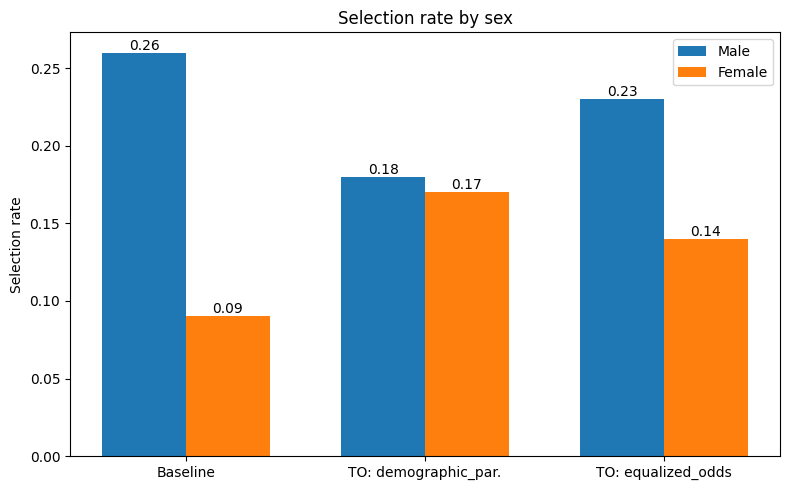

Plot saved : selection_rate_by_sex.png


In [30]:
#Cell 4

import os
os.makedirs("output", exist_ok=True)
tab = pd.DataFrame([evaluate("Baseline", pred0),
                    evaluate("TO: demographic_par.", preds["demographic_parity"]),
                    evaluate("TO: equalized_odds", preds["equalized_odds"])]).round(2)
print(tab.to_string(index=False))
tab.to_csv("output/comparison_table.csv", index=False)

x = np.arange(len(tab)); w = 0.35
plt.figure(figsize=(8, 5))
b1 = plt.bar(x - w/2, tab["SEL_M"], w, label="Male")
b2 = plt.bar(x + w/2, tab["SEL_F"], w, label="Female")
plt.bar_label(b1, fmt="%.2f"); plt.bar_label(b2, fmt="%.2f")
plt.xticks(x, tab["MODEL"]); plt.ylabel("Selection rate")
plt.title("Selection rate by sex"); plt.legend()
plt.tight_layout(); plt.savefig("selection_rate_by_sex.png", dpi=150); plt.show()
print("Plot saved : selection_rate_by_sex.png")